
# **<font color="Navy"><center> Elaboración de material didáctico para la asignatura Cambio Climático </font>**
## **<font color="RoyalBlue"><center> Jupiter Notebook-Modelo climático FaIR </font>**
### **<font color="DodgerBlue"> Visibilizar el efecto de las emisiones de gases de efecto invernadero en el sistema climático. </font>**

<p style="font-size:18px; margin-top:20px;">
<strong>Autor:</strong> Arturo Pulido Balderas y Dr. Jorge Luis García Franco <br>
<strong>Escuela Nacional de Ciencias de la Tierra (ENCiT)</strong><br>
<strong>Universidad Nacional Autónoma de México (UNAM)
</p>
<left>
<img src="files/ENCIT_logo.png" alt="ENCiT Logo"
     style="width:280px; margin-top:20px;">
<left>
<img src="files/unam.png" alt="UNAM Logo"
     style="width:220px; margin-top:20px;">

### **<font color="Navy"> 1.- Introducción-modelos de cambio climático </font>**
El cambio climático es un fenómeno a escala planetaria considerado una de las principales amenazas para las sociedades y los ecosistemas. Dicho fenómeno es generado por el incremento antropogénico en la concentración de gases de efecto invernadero en la atmósfera (IPCC, 2018). El aumento global de las temperaturas, nivel medio del mar y cambios en las condiciones en la que se desarrollan los fenómenos meteorológicos extremos tienen afectaciones a corto y largo plazo cuyo entendimiento y pronóstico resulta de interés para muchas ramas y aristas de las Ciencias de la Tierra (WMO, 2024; IPCC, 2019).

Los modelos climáticos son simulaciones matemáticas que permiten a los científicos estudiar, comprender y predecir los cambios en las variables del sistema climático. Por ejemplo, tasas de emisión de gases de efecto invernadero, cambios en el forzamiento radiatio e interacción entre variables"(USDA 2026)"


John von Neumann, científico húngaro-estadounidense, artífice de la arquitectura matemática que utilizan las computadoras actuales, propuso la posibilidad de simular los procesos atmosféricos utilizando modelos climáticos. El primer modelo numérico de circulación atmosférica fue desarrollado a mediados de la década de 1950 en el Institute for Advance Study Princeton (Universidad de Granada, 2026).


### **<font color="Navy"> 2.- Historia de los modelos climáticos </font>**

<center>
<img src="files/Historia.png" alt="Historia"
     style="width:1000px; margin-top:20px;">
</center>


En la actualidad, los modelos climáticos se desarrollan considerando las interacciones entre los componentes del sistema climático, atmósfera, criosfera, biósfera (vegetación), ciclos biogeoquímicos, entre otros.  (Edwards, 2010).
La complejidad de los modelos climáticos depende la cantidad de variables implementadas, la complejidad de las ecuaciones que describen su comportamiento y su escala temporal en 3 componentes principales:

Dominio: Espacio físico (regional / global).

Malla: Escala de análisis (distribución geométrica).

Resolución: Distancia promedio entre los puntos de la malla.


<center>
<img src="files/Dominio.png" alt="Dominio"
     style="width:700px; margin-top:20px;">
</center>

<center>
<img src="files/malla.png" alt="Dominio"
     style="width:700px; margin-top:20px;">
</center>

<center>
<img src="files/Grid.png" alt="Dominio"
     style="width:700px; margin-top:20px;">
</center>

### **<font color="Navy"> 3.- FaIR (Finite Amplitude Impulse Response simple climate model) </font>**
En la actualidad, los modelos climáticos de desarrollan y actualizan basados en la información científica proporcionada por el Coupled Model Intercomparison Project (CMIP-6) con las proyecciones del Intergovernmental Panel on Climate Change (IPCC). Esto permite que los modelos trabajen bajo las mismas bases científicas y puedan ser comparados entre sí (Smith et al., 2018).

FaIR (Finite Amplitude Impulse Response simple climate model) es un modelo climático que permite calcular el forzamiento radiativo derivado de los cambios en la concentración atmosférica de los gases de efecto invernadero y aersololes. 

Existen dos versiones principales:

FaIR v1.0 Estima el efecto del dióxido de carbono (CO2) junto con variables del ciclo biogeoquímico del carbono. 

FaIR v1.3 Evalúa el efecto del resto de gases de efecto invernadero y aerosoles atmosféricos (Smith et al., 2018).

Principales variables del modelo FaIR v1.3 (Smith et al., 2018):

<center>
<img src="files/variables.png" alt="Dominio"
     style="width:700px; margin-top:20px;">
</center>


### **<font color="Navy"> 4.- Modelación FaIR (Finite Amplitude Impulse Response simple climate model) </font>**
Utilizando Python se instala el paquete del modelo FaIR

```bash
pip install fair

In [26]:
from fair import FAIR

Posteriormente, se cargan las librerías necesarias para trabajar la información del modelo.

In [27]:
import numpy as np
import pandas as pd
import copy
import xarray as xr
import matplotlib.pyplot as plt


El siguiente código permite delimitar los parámetros para producir y ajustar los diagramas.


```python
def lineplot_setup(xmin, xmax, xlab, ylab, ymin=None, ymax=None, title=None, legend=False)
 ```

```python
    xmin : float
        Establece el valor mínimo del eje X.
    xmax : float
        Establece el valor máximo del eje X.
    xlab : str
        Descripción de la variable en el eje X.
    ylab : str
         Descripción de la variable en el eje Y.
    ymin : float, opcional
        Establece el valor mínimo del eje Y (por defecto es None, no se ajusta).
    ymax : float, opcional
      Establece el valor máximo del eje Y (por defecto es None, no se ajusta).
    title : str, opcional
       Utilizado para nombrar el gráfico
    legend : bool, opcional
#Permite asignar una leyenda descriptiva al gráfico.       
#(fontsize=numero)
#Permite ajustar el tamaño del tipo de letra
    plt.grid(linestyle='--', alpha=0.66)
    plt.minorticks_on()
#Establece la cuadrícula del gráfico.
```

Establecemos la variable f1 del modelo FaIR, en este caso corresponde a los escenarios de emisión del Intergovernmental Panel on Climate Change (IPCC).

In [28]:
from fair import FAIR
f1 = FAIR()

Posteriormente, se define la escala temporal del modelo, en este caso se efectuará la simulación climática desde el año 1750 hasta 2100 considerando todos los años (1) (350 años en total).

In [29]:
f1.define_time(1750, 2100, 1)

Después, se asignan los escenarios de emisión IPCC a la variable f1.

In [30]:
scenarios = ['ssp119', 'ssp126', 'ssp245', 'ssp370', 'ssp434', 'ssp460', 'ssp534-over', 'ssp585']
f1.define_scenarios(scenarios)

Se importan los módulos y propiedades del modelo.

In [31]:
from fair import FAIR
from fair.io import read_properties
from fair.interface import fill, initialise
from fair.earth_params import seconds_per_year

Se cargan al programa las propiedades de los gases de efecto invernadero que utiliza el modelo.

In [32]:
species, properties = read_properties()
f1.define_species(species, properties)

Se utiliza la base de datos 4xCO2_cummins_ebm3.csv 
Dicho archivo contiene estimaciones de los cambios en el sistema climático producidos por la alteración del balance radiativo derivados de la emisión de CO2. 
La base de datos estará disponible para los estudiantes del curso y cada uno deberá ajustar el código para mostrar la ruta al archivo desde sus computadoras. Asimismo, deberán guardarlo en la carpeta de su entrono de trabajo.

In [33]:
df = pd.read_csv("4xCO2_cummins_ebm3.csv")

HadGEM3-GC3.1 Es un modelo desarrollado en el Reino Unido perteneciente al Coupled Model Intercomparison Project Phase 6 (CMIP6). Permite simular el efecto de las emisiones antropogénicas de gases de efecto invernadero considerando los efectos de la interacción atmósfera-hidrósfera y aerosoles atmosféricos (Jones et al., 2024).

In [34]:
df = pd.read_csv("4xCO2_cummins_ebm3.csv")
models = ['HadGEM3-GC31-MM']
configs = []

for imodel, model in enumerate(models):
    for run in df.loc[df['model']==model, 'run']:
        configs.append(f"{model}_{run}")
f1.define_configs(configs)

In [35]:
f1.configs

['HadGEM3-GC31-MM_r1i1p1f3']

Se calibran los parámetros de HadGEM3-GC3.1 para el modelo FaIR.

In [36]:
model_name=configs[0]
model_name

'HadGEM3-GC31-MM_r1i1p1f3'

Se configuran las propiedades de las variables, en este caso corresponde al comportamiento de los de gases de efecto invernadero en los escenarios de emisión IPCC. 

In [52]:
f1.allocate()
f1.fill_species_configs()
f1.fill_from_rcmip()

In [40]:
f1.emissions

<xarray.DataArray (timepoints: 350, scenario: 8, config: 1, specie: 64)> Size: 1MB
array([[[[ 9.50561989e-03,  2.97464607e-01,             nan, ...,
                      nan,             nan,             nan]],

        [[ 9.50561989e-03,  2.97464607e-01,             nan, ...,
                      nan,             nan,             nan]],

        [[ 9.50561989e-03,  2.97464607e-01,             nan, ...,
                      nan,             nan,             nan]],

        ...,

        [[ 9.50561989e-03,  2.97464607e-01,             nan, ...,
                      nan,             nan,             nan]],

        [[ 9.50561989e-03,  2.97464607e-01,             nan, ...,
                      nan,             nan,             nan]],

        [[ 9.50561989e-03,  2.97464607e-01,             nan, ...,
                      nan,             nan,             nan]]],

...
       [[[-1.11917246e+01, -2.36558648e+00,             nan, ...,
                      nan,             nan,             nan]],

        [[-5.77692565e+00, -2.81760024e+00,             nan, ...,
                      nan,             nan,             nan]],

        [[ 1.50987936e+01, -4.75178148e+00,             nan, ...,
                      nan,             nan,             nan]],

        ...,

        [[ 2.45797522e+01, -1.88412841e+00,             nan, ...,
                      nan,             nan,             nan]],

        [[-1.94208703e+01, -7.14998000e-01,             nan, ...,
                      nan,             nan,             nan]],

        [[ 1.28143025e+02, -1.42682239e+00,             nan, ...,
                      nan,             nan,             nan]]]],
      shape=(350, 8, 1, 64))
Coordinates:
  * timepoints  (timepoints) float64 3kB 1.75e+03 1.752e+03 ... 2.1e+03
  * scenario    (scenario) <U11 352B 'ssp119' 'ssp126' ... 'ssp585'
  * config      (config) <U24 96B 'HadGEM3-GC31-MM_r1i1p1f3'
  * specie      (specie) <U43 11kB 'CO2 FFI' ... 'Equivalent effective strato...

In [41]:
f1.emissions.to_dataframe(name="datos")

datos
timepoints scenario config                   specie                                                
1750.5     ssp119   HadGEM3-GC31-MM_r1i1p1f3 CO2 FFI                                       0.009506
                                             CO2 AFOLU                                     0.297465
                                             CO2                                                NaN
                                             CH4                                          19.019783
                                             N2O                                           0.086022
...                                                                                             ...
2099.5     ssp585   HadGEM3-GC31-MM_r1i1p1f3 Contrails                                          NaN
                                             Light absorbing particles on snow and ice          NaN
                                             Stratospheric water vapour                         NaN
                                             Land use                                           NaN
                                             Equivalent effective stratospheric chlorine        NaN

[179200 rows x 1 columns]

**Interpretación:**

**Timepoints:** Escala temporal del modelo.

**Scenario:** Escenarios de emisión SSP.

**Config:** Modelo climático, en este caso los parámetros de HadGEM3-GC3.1 aplicados a FaIR.

**Specie:** Gases de efecto invernadero. Por ejemplo, dióxido de carbono (CO2), metano (CH4) etc.


Posteriormente, se define la concentración inicial de los gases (especies) en la atmósfera. Asimismo, se establecen el forzamiento radiativo, temperatura, acumulación y retención de emisiones iniciales en 0.

In [42]:
initialise(f1.concentration, f1.species_configs['baseline_concentration'])
initialise(f1.forcing, 0)
initialise(f1.temperature, 0)
initialise(f1.cumulative_emissions, 0)
initialise(f1.airborne_emissions, 0)

Se transfieren a FaIR las propiedades y parámetros de HadGEM3-GC3.1 para simular el forzamiento radiativo a distintas profundidades de los océanos considerando (Timepoints, Scenario, Config y Specie) para los escenarios de emisión SSP.

In [43]:
for config in configs:
    model, run = config.split('_')
    condition = (df['model']==model) & (df['run']==run)
    fill(f1.climate_configs['ocean_heat_capacity'], df.loc[condition, 'C1':'C3'].values.squeeze(), config=config)
    fill(f1.climate_configs['ocean_heat_transfer'], df.loc[condition, 'kappa1':'kappa3'].values.squeeze(), config=config)
    fill(f1.climate_configs['deep_ocean_efficacy'], df.loc[condition, 'epsilon'].values[0], config=config)

In [44]:
f1.run()

Running 8 projections in parallel:   0%|          | 0/350 [00:00<?, ?timesteps/s]

In [45]:
f1.emissions.specie

<xarray.DataArray 'specie' (specie: 64)> Size: 11kB
array(['CO2 FFI', 'CO2 AFOLU', 'CO2', 'CH4', 'N2O', 'Sulfur', 'BC', 'OC',
       'NH3', 'NOx', 'VOC', 'CO', 'CFC-11', 'CFC-12', 'CFC-113', 'CFC-114',
       'CFC-115', 'HCFC-22', 'HCFC-141b', 'HCFC-142b', 'CCl4', 'CHCl3',
       'CH2Cl2', 'CH3Cl', 'CH3CCl3', 'CH3Br', 'Halon-1202', 'Halon-1211',
       'Halon-1301', 'Halon-2402', 'CF4', 'C2F6', 'C3F8', 'c-C4F8', 'C4F10',
       'C5F12', 'C6F14', 'C7F16', 'C8F18', 'NF3', 'SF6', 'SO2F2', 'HFC-125',
       'HFC-134a', 'HFC-143a', 'HFC-152a', 'HFC-227ea', 'HFC-23', 'HFC-236fa',
       'HFC-245fa', 'HFC-32', 'HFC-365mfc', 'HFC-4310mee', 'NOx aviation',
       'Solar', 'Volcanic', 'Aerosol-radiation interactions',
       'Aerosol-cloud interactions', 'Ozone', 'Contrails',
       'Light absorbing particles on snow and ice',
       'Stratospheric water vapour', 'Land use',
       'Equivalent effective stratospheric chlorine'], dtype='<U43')
Coordinates:
  * specie   (specie) <U43 11kB 'CO2 FFI' ... 'Equivalent effective stratosph...

### **<font color="Navy"> 5.- Emisiones de metano (CH4) de los escenarios de emisión SSP. </font>**
El metano (CH4) es un compuesto gaseoso constituido por un átomo de carbono y cuatro de hidrógeno. Es considerado el segundo gas de efecto invernadero que más contribuye a los efectos del cambio climático.

Se estima que durante su vida media en la atmósfera, cada tonelada de metano posee los mismos efectos de retención calorífica equivalentes a 80 toneladas de dióxido de carbono (CO2) en ciertas regiones del espectro infrarojo (IEA,2026). El estudio de núcleos de hielo de la Antártida y Groenlandia han permitido a los científicos determinar su concentración histórica en la atmósfera. A su vez, el aumento de las temperaturas globales propicia la liberación de metano de los reservorios naturales como el permafrost. Dicho proceso constituye una retroalimentación climática positiva (NASA, 2026).

Para graficar las emisiones de metano utilizamos el código descrito en la línea 35 para producir y ajustar el diagrama

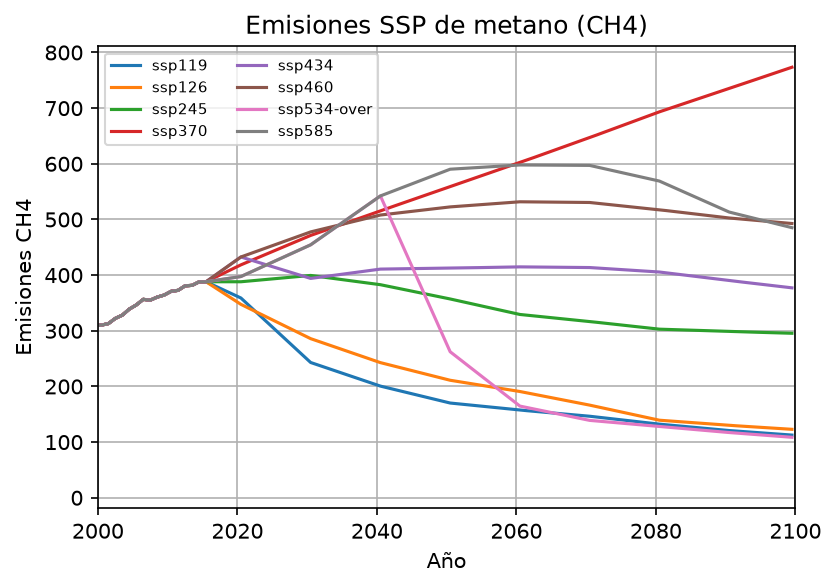

In [46]:
plt.figure(figsize=(6,4), dpi=150)

for scen in f1.scenarios:
    plt.plot(
        f1.timepoints,
        f1.emissions.sel(specie='CH4', scenario=scen).squeeze(),
        label=scen
    )

plt.xlim(2000, 2100)
plt.xlabel('Año')
plt.ylabel('Emisiones CH4')
plt.title('Emisiones SSP de metano (CH4)')
plt.grid(True)

plt.legend(fancybox=True, ncol=2, fontsize=7)
plt.show()


### **<font color="Navy"> 6.- Emisiones de dióxido de carbono (CO2) de los escenarios de emisión SSP. </font>**
El dióxido de carbono es un compuesto gaseoso formado por dos átomos de oxígeno y uno de carbono (CO2). Es un gas indispensable para la estabilidad de los ecosistemas de nuestro planeta, puesto que es utilizado para los procesos de fotosíntesis de organismos con cloroplastos.

The National Oceanic and Atmospheric Administration (NOAA) (Lindsey, R 2026) clasifica al dióxido de carbono como el gas de efecto invernadero más importante para la estabilidad climática del planeta. Puesto que si la atmósfera careciera completamente de CO2 la temperatura media global estaría por debajo de los -18 °C.

El Laboratorio de Cambio Climático de la NASA sostiene que la cantidad de CO2 en la atmósfera no había superado las 300 partes por millón desde hace más de 800,000 años. Las actividades antropocéntricas han ocasionado un incremento drástico en la cantidad de dióxido de carbono en la atmósfera hasta las 430 ppm en 2026 (NASA, 2026).

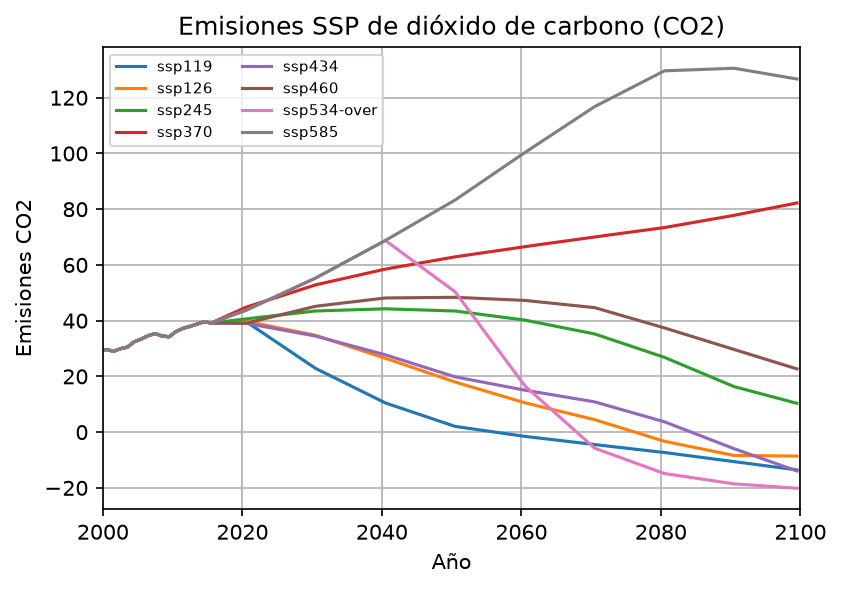

In [47]:
plt.figure(figsize=(6,4), dpi=150)

for scen in f1.scenarios:
    plt.plot(
        f1.timepoints,
        f1.emissions.sel(specie='CO2', scenario=scen).squeeze(),
        label=scen
    )

plt.xlim(2000, 2100)
plt.xlabel('Año')
plt.ylabel('Emisiones CO2')
plt.title('Emisiones SSP de dióxido de carbono (CO2)')
plt.grid(True)

plt.legend(fancybox=True, ncol=2, fontsize=7)
plt.show()

### **<font color="Navy"> 7.- Emisiones de óxidos de nitrógeno (NOx) de los escenarios de emisión SSP. </font>**
Los óxidos de Nitrógeno (NOx) son compuestos gaseosos que pueden tanto emitirse directamente a la atmósfera como formarse por reacciones químicas en ella. 
Los NOx participan en reacciones fotoquímicas responsables de la formación de ozono (O3) troposférico, considerado un gas de efecto invernadero a baja altitud. Asimismo, los NOx reducen los niveles de hidroxilos (OH) en la atmósfera, alterando los tiempos de retención de gases de efecto invernadero como el metano (CH4). Las emisiones y reacciones fotoquímicas de los NOx se monitorean principalmente mediante satélites de observación de la Tierra (NASA, 2024). 

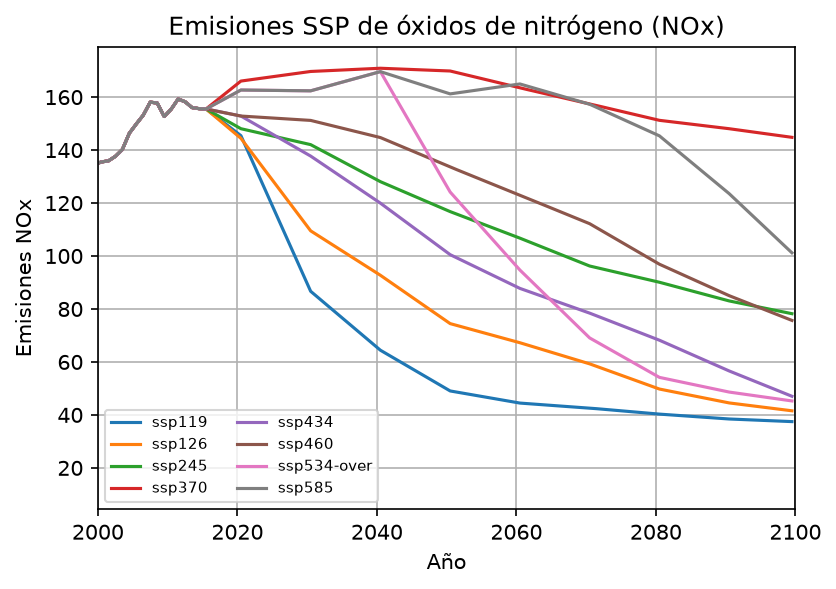

In [48]:
plt.figure(figsize=(6,4), dpi=150)

for scen in f1.scenarios:
    plt.plot(
        f1.timepoints,
        f1.emissions.sel(specie='NOx', scenario=scen).squeeze(),
        label=scen
    )

plt.xlim(2000, 2100)
plt.xlabel('Año')
plt.ylabel('Emisiones NOx')
plt.title('Emisiones SSP de óxidos de nitrógeno (NOx)')
plt.grid(True)

plt.legend(fancybox=True, ncol=2, fontsize=7)
plt.show()

### **<font color="Navy"> 8.- Emisiones de clorofluorocarbonos (CFC-11) de los escenarios de emisión SSP. </font>**
Los clorofluorocarbonos (CFC) son moléculas constituidas principalmente por cloro (Cl), flúor (F) y carbono (C).  Los CFC comenzaron a ser utilizados en procesos industriales desde inicios de los 1900´s y tuvieron su periodo de máxima emisión entre 1950-1960. Al ser transportados a la estratósfera interactúan con la radiación ultravioleta irrumpiendo los procesos de formación y disociación del ozono (O3) (Ciclo de Chapman), propiciando un decrecimiento en la concentración de ozono. (NOAA, 2026).

La capa de ozono es la región estratosférica que por su alta concentración de (O3) absorbe aproximadamente el 97% de la radiación ultravioleta de alta frecuencia (UV-A y UV-B). Derivado de los proyectos de investigación de Paul J. Crutzen, Mario J. Molina y F. Sherwood Rowland (Premio Nobel de Química-1995) entró en vigor el Protocolo de Montreal (1989) con el objetivo eliminar las emisiones de CFC a nivel internacional (UNEP,2018; William H.,2026) Los escenarios SSP contemplan el cumplimiento del Protocolo de Montreal a corto y largo plazo. 


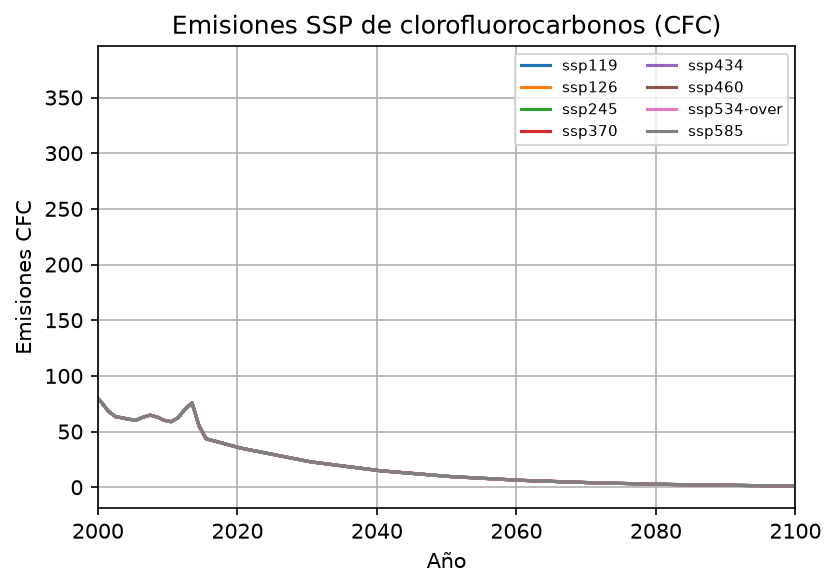

In [49]:
plt.figure(figsize=(6,4), dpi=150)

for scen in f1.scenarios:
    plt.plot(
        f1.timepoints,
        f1.emissions.sel(specie='CFC-11', scenario=scen).squeeze(),
        label=scen
    )

plt.xlim(2000, 2100)
plt.xlabel('Año')
plt.ylabel('Emisiones CFC')
plt.title('Emisiones SSP de clorofluorocarbonos (CFC)')
plt.grid(True)

plt.legend(fancybox=True, ncol=2, fontsize=7)
plt.show()

### **<font color="Navy"> 9.- Interpretación  </font>**
El IPCC (Intergovernmental Panel on Climate Change) surgió en 1988 como una iniciativa conjunta entre la World Meteorological Organization (WMO) y The United Nations Environment Programme (UNEP). Su misión es facilitar los conocimientos respecto a las causas, repercusiones, efectos y estrategias de adaptación y mitigación frente a la crisis climática (IPCC, 2018). El primer Assesment Report (AR1) se publicó en 1990. Desde entonces se han publicado 6 ediciones. Los Shared Socioeconomic Pathways (SSP) son escenarios de cambio climático basados en los cambios en el balance radiativo derivados de las distintas posibles tasas de emisión de gases de efecto invernadero (University of Oxford, 2026).

SSP-1 Sustainability 
El SSP-1 es el escenario más optimista. Prevé las mejores condiciones para la implementación de estrategias de adaptación, mitigación, inversión en desarrollo sostenible, educación ambiental, así como el cumplimiento exitoso de políticas ambientales derivadas de la cooperación internacional que limitan gradualmente la emisión de gases de efecto invernadero.


SSP-2 Middle of the Road
El SSP-2 define un escenario en el que la sociedad y las políticas ambientales continúan de acuerdo con las tendencias históricas. La desigualdad, políticas públicas y cooperación internacional limitada continúan y definen las emisiones.

SSP-3 Regional Rivalry
El SSP-3 define un futuro en el cuál los países compiten por la sobreexplotación de recursos y se limitan significativamente los esfuerzos de adaptación, mitigación y educación ante la crisis climática.

SSP-4 Inequality
SSP-4 surge de un posible futuro con desigualdad en el acceso a tecnologías sostenibles junto con una creciente inversión en energías y procesos industriales con altas emisiones.

SSP-5 Fossil-fueled Development
define el peor escenario posible en relación con la emisión de gases de efecto invernadero. Se impulsa el desarrollo energético y económico con las mayores tasas de emisión junto a la sobreexplotación de los recursos naturales. Menor inversión en educación ambiental y políticas públicas (Riahi et al., 2017; O’Neill et al., 2017).

### **<font color="Navy"> 10.- Conclusión <font>**
Los modelos climáticos constituyen una de las herramientas más importantes para el estudio del cambio climático. Permiten a los científicos comprender la interacción y comportamiento de las variables del sistema climático, así como el diseño estrategias de adaptación y mitigación basados en los posibles escenarios de emisión de gases de efecto invernadero.

En la actualidad la modelación climática representa uno de los componentes indispensables para el desarrollo de las Ciencias de la Tierra por su capacidad de integrar componentes fisicomatemáticos para simular el comportamiento de las variables del sistema climático y su interacción con las esferas terrestres a corto y largo plazo (Bordoni et al., 2025).

### **<font color="Navy">11.- Referencias</font>**

1. Bordoni, S., Kang, S. M., Shaw, T. A., Simpson, I. R., & Zanna, L. (2025). The futures of climate modeling. Climate and Atmospheric Science, 8(1). https://doi.org/10.1038/s41612-025-00955-8
2. Edwards, P. N. (2010). History of climate modeling. Wiley Interdisciplinary Reviews: Climate Change, 2(1), 128–139. https://doi.org/10.1002/wcc.95
3. How NASA Builds Resilience with Climate Models (NASA, 2021). Global Precipitation Measurement Mission. https://gpm.nasa.gov/applications/how-nasa-builds-resilience-climate-models
4. Intergovernmental Panel on Climate Change (IPCC) (2018). Summary for Policymakers. In: Global Warming of 1.5°C. Cambridge University Press, Cambridge, UK and New York, pp. 3-24. doi:10.1017/9781009157940.001
5. Intergovernmental Panel on Climate Change (IPCC) (2019). https://www.ipcc.ch/
6. International Energy Agency (IEA, 2026). Methane. https://www.iea.org/reports/global-methane-tracker-2026
7. Jones, G. S., Andrews, M. B., Andrews, T., Blockley, E., Ciavarella, A., Christidis, N., Cotterill, D. F., Lott, F. C., Ridley, J., & Stott, P. A. (2024). The HadGEM3-GC3.1 Contribution to the CMIP6 Detection and Attribution Model Intercomparison Project. Journal of Advances in Modeling Earth Systems, 16(8). https://doi.org/10.1029/2023ms004135
8. Lindsey, R. (2026). Climate change: atmospheric carbon dioxide. NOAA Climate.gov. https://www.climate.gov/news-features/understanding-climate/climate-change-atmospheric-carbon-dioxide
9. NASA (2024). NASA Earthdata; Earth Science Data Systems, NASA. https://www.earthdata.nasa.gov/topics/atmosphere/nitrogen-oxides
10. NASA (2026). Carbon Dioxide – Earth Indicator. NASA Science. https://science.nasa.gov/earth/explore/earth-indicators/carbon-dioxide/
11. NASA (2026). Methane vital signs – Climate Change. https://climate.nasa.gov/vital-signs/methane/?intent=121
12. NOAA (2026). NOAA Global Monitoring Laboratory. https://gml.noaa.gov/hats/about/cfc.html
13. O'Neill, B. C., Kriegler, E., Riahi, K., Ebi, K. L., Hallegatte, S., Carter, T. R., Mathur, R., & van Vuuren, D. P. (2013). A new scenario framework for climate change research: the concept of shared socioeconomic pathways. Climatic Change, 122(3), 387–400. https://doi.org/10.1007/s10584-013-0905-2
14. Riahi, K., van Vuuren, D. P., Kriegler, E., Edmonds, J., O'Neill, B. C., Fujimori, S., Bauer, N., Calvin, K., Dellink, R., Fricko, O., Lutz, W., Popp, A., Cuaresma, J. C., KC, S., Leimbach, M., Jiang, L., Kram, T., Rao, S., Emmerling, J., … Tavoni, M. (2017). The Shared Socioeconomic Pathways and their energy, land use, and greenhouse gas emissions implications: An overview. Global Environmental Change, 42, 153–168. https://doi.org/10.1016/j.gloenvcha.2016.05.009
15. Smith, C. J., Forster, P. M., Allen, M., Leach, N., Millar, R. J., Passerello, G. A., & Regayre, L. A. (2018). FAIR v1.3: a simple emissions-based impulse response and carbon cycle model. Geoscientific Model Development, 11(6), 2273–2297. https://doi.org/10.5194/gmd-11-2273-2018
16. United Nations Environment Programme (UNEP, 2018). About Montreal Protocol. https://www.unep.org/ozonaction/who-we-are/about-montreal-protocol
17. Universidad de Granada (2026). John von Neumann. https://www.ugr.es/~eaznar/von_neumann.htm
18. University of Oxford (2026). IPCC Scenarios Data Explorer. https://ourworldindata.org/explorers/ipcc-scenarios
19. USDA (2026). U.S. Department of Agriculture: Basics of Global Climate Models. https://www.climatehubs.usda.gov/hubs/northwest/topic/basics-global-climate-models
20. William, H. (2026). Stratospheric Ozone Formation. College of Earth and Mineral Sciences, The Pennsylvania State University. https://courses.ems.psu.edu/meteo300/node/595
21. World Meteorological Organization (WMO) (2024). State of the Global Climate. https://wmo.int/publication-series/state-of-global-climate-2024